In [ ]:
!pip install -q torch torchvision scikit-learn matplotlib


In [ ]:
from torchvision import datasets

src = datasets.ImageFolder("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged")
tgt = datasets.ImageFolder("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected")

print("Source classes:", src.classes)
print("Target classes:", tgt.classes)
print("Source samples:", len(src))
print("Target samples:", len(tgt))


Source classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
Target classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
Source samples: 25079
Target samples: 2059


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
!python dann_mcc_mobilenetv2.py \
  --source_path "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged" \
  --target_unlabeled_path "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled" \
  --target_labeled_path "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected" \
  --save_path "/content/drive/MyDrive/MCC_project/best_dann_mcc.pth" \
  --epochs 30


Epoch [1/30] Target Acc: 0.1404
Epoch [2/30] Target Acc: 0.1510
Epoch [3/30] Target Acc: 0.1855
Epoch [4/30] Target Acc: 0.1705
Epoch [5/30] Target Acc: 0.1918
Epoch [6/30] Target Acc: 0.1807
Epoch [7/30] Target Acc: 0.2438
Epoch [8/30] Target Acc: 0.1909
Epoch [9/30] Target Acc: 0.2317
Epoch [10/30] Target Acc: 0.2477
Epoch [11/30] Target Acc: 0.1899
Epoch [12/30] Target Acc: 0.2433
Epoch [13/30] Target Acc: 0.2433
Epoch [14/30] Target Acc: 0.1676
Epoch [15/30] Target Acc: 0.1870
Epoch [16/30] Target Acc: 0.2312
Epoch [17/30] Target Acc: 0.2997
Epoch [18/30] Target Acc: 0.2783
Epoch [19/30] Target Acc: 0.2749
Epoch [20/30] Target Acc: 0.2462
Epoch [21/30] Target Acc: 0.2992
Epoch [22/30] Target Acc: 0.2739
Epoch [23/30] Target Acc: 0.2851
Epoch [24/30] Target Acc: 0.2623
Epoch [25/30] Target Acc: 0.2841
Epoch [26/30] Target Acc: 0.3152
Epoch [27/30] Target Acc: 0.2676
Epoch [28/30] Target Acc: 0.2564
Epoch [29/30] Target Acc: 0.2462
Epoch [30/30] Target Acc: 0.2598

Classification Rep

In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd * grad_output, None


class DANN_MCC(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        base = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        self.feature = base.features
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        self.feat_dim = 1280
        self.classifier = nn.Linear(self.feat_dim, num_classes)
        self.domain = nn.Sequential(
            nn.Linear(self.feat_dim, 256), nn.ReLU(), nn.Linear(256, 2)
        )

    def forward(self, x, lambd=1.0):
        f = self.feature(x)
        f = self.pool(f).view(x.size(0), -1)
        y = self.classifier(f)
        d = self.domain(GRL.apply(f, lambd))
        return y, d



In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = DANN_MCC(num_classes=7).to(DEVICE)
model.load_state_dict(
    torch.load("/content/drive/MyDrive/MCC_project/best_dann_mcc.pth",
               map_location=DEVICE)
)
model.eval()


DANN_MCC(
  (feature): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=1e-0

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

target_ds = datasets.ImageFolder(
    "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected",
    transform=transform
)

target_loader = DataLoader(
    target_ds, batch_size=1, shuffle=True
)

class_names = target_ds.classes


In [ ]:
from collections import defaultdict

def visualize_predictions(model, loader, class_names, samples_per_class=5):
    model.eval()
    collected = defaultdict(list)

    with torch.no_grad():
        for img, label in loader:
            img = img.to(DEVICE)
            logits, _ = model(img, 0)
            pred = logits.argmax(1).item()
            gt = label.item()

            if len(collected[gt]) < samples_per_class:
                collected[gt].append((img.cpu(), gt, pred))

            if all(len(collected[i]) >= samples_per_class for i in range(len(class_names))):
                break

    for cls_idx in range(len(class_names)):
        plt.figure(figsize=(15,3))
        for i, (img, gt, pr) in enumerate(collected[cls_idx]):
            img = img.squeeze().permute(1,2,0)
            img = img * torch.tensor([0.229,0.224,0.225]) + torch.tensor([0.485,0.456,0.406])
            img = img.clamp(0,1)

            plt.subplot(1, samples_per_class, i+1)
            plt.imshow(img)
            color = "green" if gt == pr else "red"
            plt.title(f"GT: {class_names[gt]}\nPred: {class_names[pr]}", color=color)
            plt.axis("off")

        plt.suptitle(f"Class: {class_names[cls_idx]}")
        plt.show()


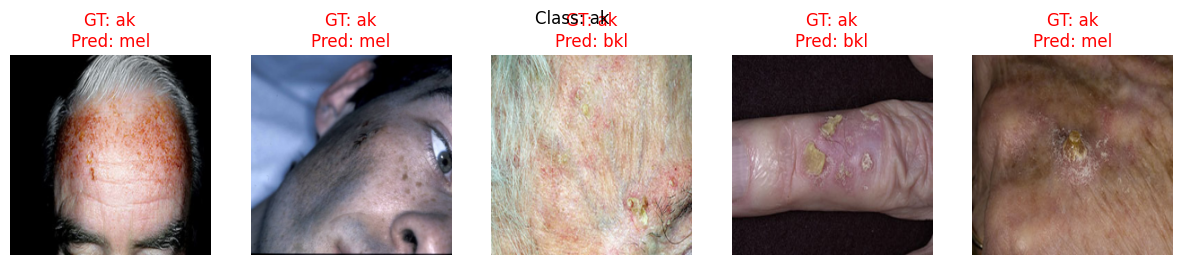

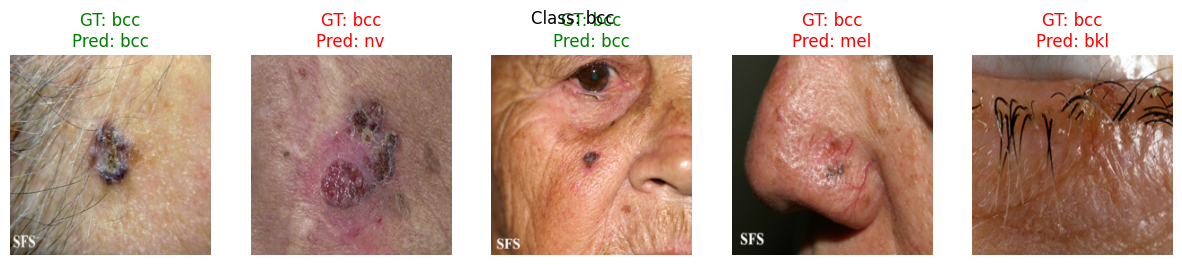

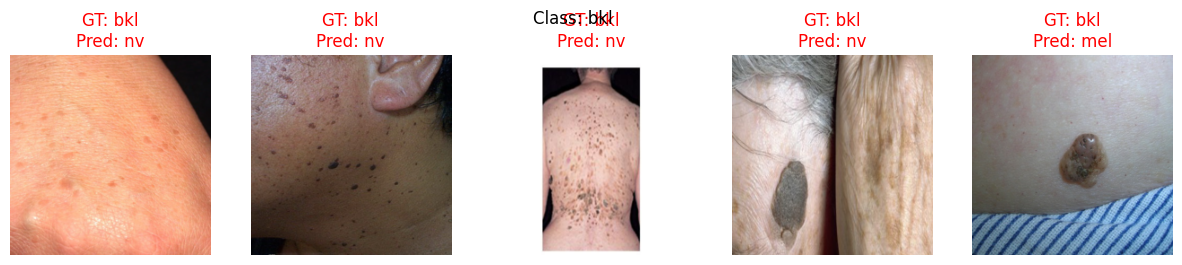

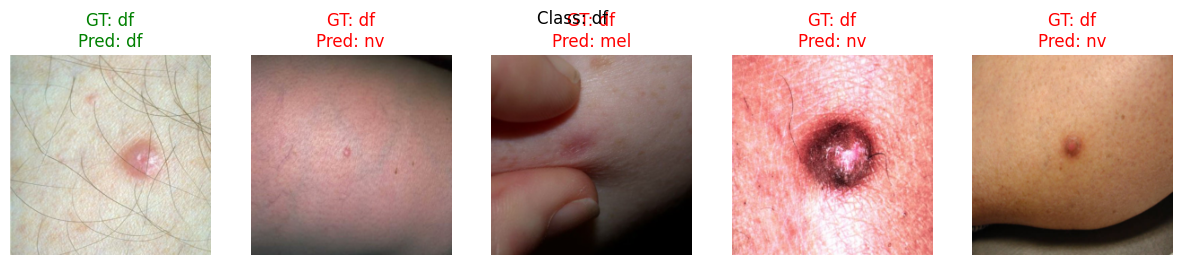

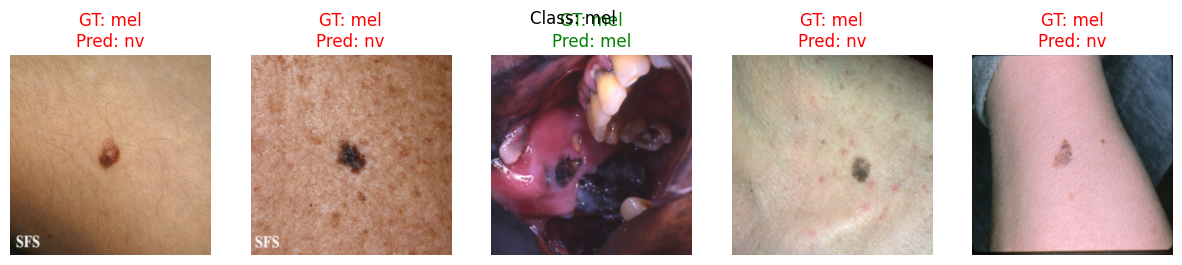

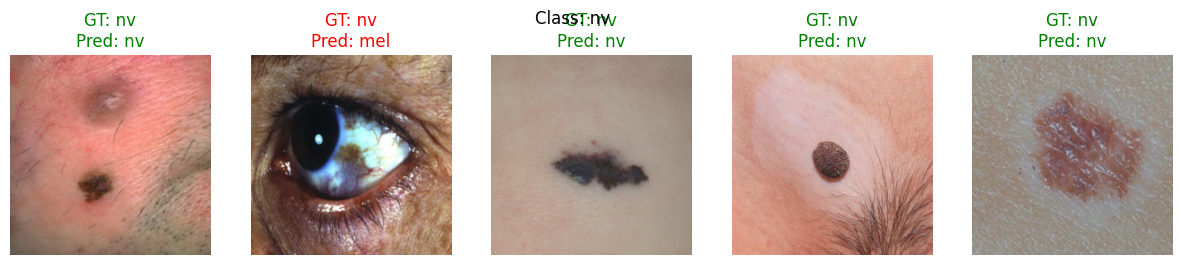

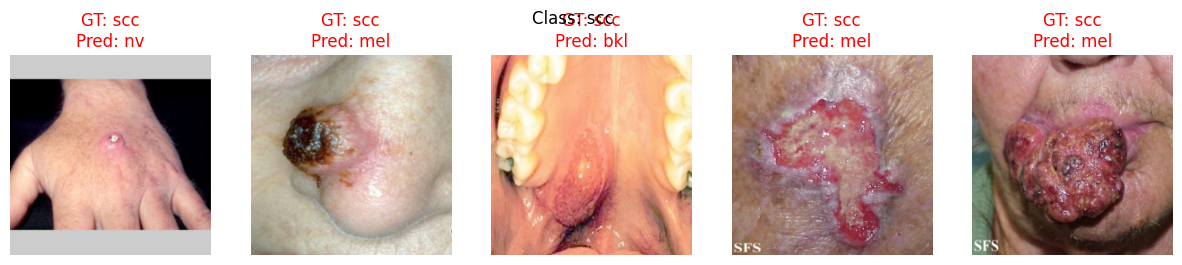

In [ ]:
visualize_predictions(
    model,
    target_loader,
    class_names,
    samples_per_class=5
)
